ENTERPRISE DEEP LEARNING SEQUENCE MODEL DEPLOYMENT SUITE
TensorFlow Version: 2.21.0
GPU Devices: []

Configuration completed.
Vocabulary Size: 20000
Maximum Sequence Length: 200
Embedding Dimension: 128
Batch Size: 128
Training Epochs: 4

Loading IMDB movie review dataset...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset loaded successfully.
Training samples: 25000
Testing samples: 25000

First five labels:
[1 0 0 1 0]

First review sequence:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480]

Training Dataset Distribution
Positive Reviews: 12500
Negative Reviews: 12500


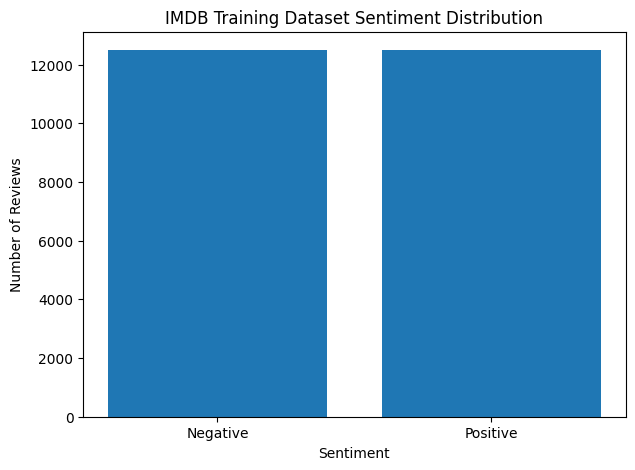


Sequence Length Statistics
Minimum Length: 11
Maximum Length: 2494
Average Length: 238.71364
Median Length: 178.0


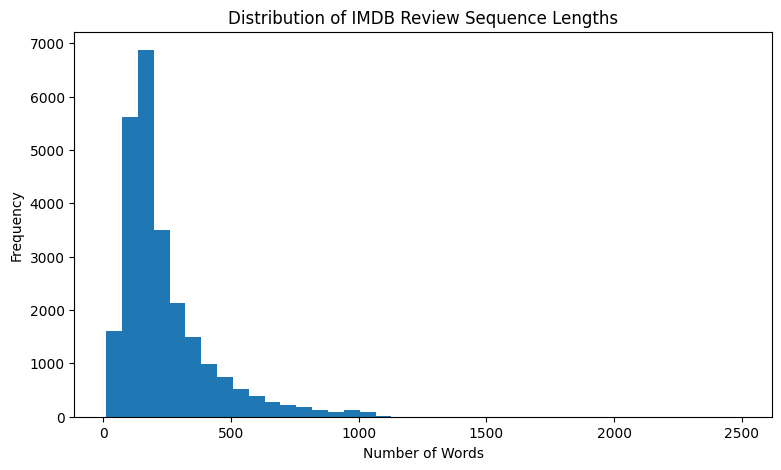


Applying sequence padding...
Training Input Shape: (25000, 200)
Testing Input Shape: (25000, 200)
Sequence preprocessing completed.

Available Deep Learning Architectures:

LSTM


Model: "LSTM_Sentiment_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


TRAINING: LSTM
Epoch 1/4
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 605ms/step - accuracy: 0.5096 - loss: 0.6959
Epoch 1: val_loss improved from None to 0.56584, saving model to Enterprise_Sequence_Model_Outputs/models/LSTM_best.keras

Epoch 1: finished saving model to Enterprise_Sequence_Model_Outputs/models/LSTM_best.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 108s 659ms/step - accuracy: 0.5344 - loss: 0.6851 - val_accuracy: 0.7804 - val_loss: 0.5658 - learning_rate: 0.0010
Epoch 2/4
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.5936 - loss: 0.6532
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 2: val_loss did not improve from 0.56584
157/157 ━━━━━━━━━━━━━━━━━━━━ 100s 637ms/step - accuracy: 0.5947 - loss: 0.6541 - val_accuracy: 0.5338 - val_loss: 0.6797 - learning_rate: 0.0010
Epoch 3/4
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 581ms/step - accuracy: 0.6156 - loss: 0.6460
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 3: val_loss 

In [ ]:

# ================================================================
# ENTERPRISE DEEP LEARNING SEQUENCE MODEL DEPLOYMENT SUITE
# Dataset: IMDB Movie Reviews
# Models: LSTM, GRU, Bidirectional LSTM
# Task: Binary Sentiment Classification
# Platform: Google Colab
# ================================================================


# ================================================================
# 1. IMPORT REQUIRED LIBRARIES
# ================================================================

import os
import json
import zipfile
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    GRU,
    Bidirectional,
    Dense,
    Dropout,
    SpatialDropout1D,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 70)
print("ENTERPRISE DEEP LEARNING SEQUENCE MODEL DEPLOYMENT SUITE")
print("=" * 70)

print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices("GPU"))


# ================================================================
# 2. CONFIGURATION
# ================================================================

VOCAB_SIZE = 20000
MAX_SEQUENCE_LENGTH = 200
EMBEDDING_DIMENSION = 128
BATCH_SIZE = 128
EPOCHS = 4

OUTPUT_DIR = "Enterprise_Sequence_Model_Outputs"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

print("\nConfiguration completed.")
print("Vocabulary Size:", VOCAB_SIZE)
print("Maximum Sequence Length:", MAX_SEQUENCE_LENGTH)
print("Embedding Dimension:", EMBEDDING_DIMENSION)
print("Batch Size:", BATCH_SIZE)
print("Training Epochs:", EPOCHS)


# ================================================================
# 3. LOAD IMDB DATASET
# ================================================================

print("\nLoading IMDB movie review dataset...")

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("\nDataset loaded successfully.")
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

print("\nFirst five labels:")
print(y_train[:5])

print("\nFirst review sequence:")
print(x_train[0][:30])


# ================================================================
# 4. DATASET EXPLORATION
# ================================================================

positive_count = np.sum(y_train == 1)
negative_count = np.sum(y_train == 0)

print("\nTraining Dataset Distribution")
print("Positive Reviews:", positive_count)
print("Negative Reviews:", negative_count)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Negative", "Positive"],
    [negative_count, positive_count]
)
plt.title("IMDB Training Dataset Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.savefig(
    os.path.join(PLOT_DIR, "dataset_distribution.png")
)
plt.show()


# ================================================================
# 5. TEXT SEQUENCE LENGTH ANALYSIS
# ================================================================

review_lengths = [len(review) for review in x_train]

print("\nSequence Length Statistics")
print("Minimum Length:", np.min(review_lengths))
print("Maximum Length:", np.max(review_lengths))
print("Average Length:", np.mean(review_lengths))
print("Median Length:", np.median(review_lengths))

plt.figure(figsize=(9, 5))
plt.hist(review_lengths, bins=40)
plt.title("Distribution of IMDB Review Sequence Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.savefig(
    os.path.join(PLOT_DIR, "sequence_length_distribution.png")
)
plt.show()


# ================================================================
# 6. SEQUENCE PADDING AND PREPROCESSING
# ================================================================

print("\nApplying sequence padding...")

x_train_padded = pad_sequences(
    x_train,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

x_test_padded = pad_sequences(
    x_test,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Training Input Shape:", x_train_padded.shape)
print("Testing Input Shape:", x_test_padded.shape)

print("Sequence preprocessing completed.")


# ================================================================
# 7. CREATE MODEL BUILDING FUNCTIONS
# ================================================================

def build_lstm_model():

    model = Sequential(name="LSTM_Sentiment_Model")

    model.add(
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIMENSION,
            input_length=MAX_SEQUENCE_LENGTH
        )
    )

    model.add(SpatialDropout1D(0.2))

    model.add(
        LSTM(
            64,
            return_sequences=True,
            dropout=0.2
        )
    )

    model.add(BatchNormalization())

    model.add(
        LSTM(
            32,
            dropout=0.2
        )
    )

    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.4))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_gru_model():

    model = Sequential(name="GRU_Sentiment_Model")

    model.add(
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIMENSION,
            input_length=MAX_SEQUENCE_LENGTH
        )
    )

    model.add(SpatialDropout1D(0.2))

    model.add(
        GRU(
            64,
            return_sequences=True,
            dropout=0.2
        )
    )

    model.add(
        GRU(
            32,
            dropout=0.2
        )
    )

    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.4))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_bilstm_model():

    model = Sequential(name="Bidirectional_LSTM_Model")

    model.add(
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIMENSION,
            input_length=MAX_SEQUENCE_LENGTH
        )
    )

    model.add(SpatialDropout1D(0.2))

    model.add(
        Bidirectional(
            LSTM(
                64,
                return_sequences=True,
                dropout=0.2
            )
        )
    )

    model.add(
        Bidirectional(
            LSTM(
                32,
                dropout=0.2
            )
        )
    )

    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.4))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ================================================================
# 8. INITIALIZE DEEP LEARNING MODELS
# ================================================================

model_builders = {
    "LSTM": build_lstm_model,
    "GRU": build_gru_model,
    "Bidirectional_LSTM": build_bilstm_model
}

models = {}
histories = {}
evaluation_results = {}

print("\nAvailable Deep Learning Architectures:")

for model_name, builder in model_builders.items():

    models[model_name] = builder()

    print("\n", "=" * 60)
    print(model_name)
    print("=" * 60)

    models[model_name].summary()


# ================================================================
# 9. TRAINING CALLBACKS
# ================================================================

def create_callbacks(model_name):

    checkpoint_path = os.path.join(
        MODEL_DIR,
        model_name + "_best.keras"
    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=0.00001,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    return callbacks


# ================================================================
# 10. TRAIN ALL THREE MODELS
# ================================================================

for model_name, model in models.items():

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    history = model.fit(
        x_train_padded,
        y_train,
        validation_split=0.2,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=create_callbacks(model_name),
        verbose=1
    )

    histories[model_name] = history

    print("\nTraining completed for:", model_name)


# ================================================================
# 11. TRAINING AND VALIDATION VISUALIZATION
# ================================================================

for model_name, history in histories.items():

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(model_name + " Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(model_name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            PLOT_DIR,
            model_name + "_training_history.png"
        )
    )

    plt.show()


# ================================================================
# 12. MODEL EVALUATION
# ================================================================

print("\n" + "=" * 70)
print("MODEL EVALUATION")
print("=" * 70)

for model_name, model in models.items():

    print("\nEvaluating:", model_name)

    test_loss, test_accuracy = model.evaluate(
        x_test_padded,
        y_test,
        verbose=1
    )

    probabilities = model.predict(
        x_test_padded,
        batch_size=BATCH_SIZE,
        verbose=1
    ).flatten()

    predictions = (probabilities >= 0.5).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    evaluation_results[model_name] = {
        "Accuracy": float(test_accuracy),
        "Loss": float(test_loss),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1_Score": float(f1),
        "Predictions": predictions,
        "Probabilities": probabilities
    }

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Negative", "Positive"],
            zero_division=0
        )
    )


# ================================================================
# 13. PERFORMANCE COMPARISON TABLE
# ================================================================

comparison_data = []

for model_name, result in evaluation_results.items():

    comparison_data.append({

        "Model": model_name,
        "Accuracy": result["Accuracy"],
        "Loss": result["Loss"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1 Score": result["F1_Score"]

    })

comparison_df = pd.DataFrame(comparison_data)

print("\nMODEL PERFORMANCE COMPARISON")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

comparison_df.to_excel(
    os.path.join(OUTPUT_DIR, "model_comparison.xlsx"),
    index=False
)


# ================================================================
# 14. ACCURACY COMPARISON GRAPH
# ================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Deep Learning Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "model_accuracy_comparison.png")
)

plt.show()


# ================================================================
# 15. LOSS COMPARISON GRAPH
# ================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Loss"]
)

plt.title("Deep Learning Model Loss Comparison")
plt.xlabel("Model")
plt.ylabel("Test Loss")
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "model_loss_comparison.png")
)

plt.show()


# ================================================================
# 16. CONFUSION MATRIX FOR EACH MODEL
# ================================================================

for model_name, result in evaluation_results.items():

    cm = confusion_matrix(
        y_test,
        result["Predictions"]
    )

    plt.figure(figsize=(6, 5))

    plt.imshow(cm, interpolation="nearest")
    plt.title(model_name + " Confusion Matrix")
    plt.colorbar()

    plt.xticks(
        [0, 1],
        ["Negative", "Positive"]
    )

    plt.yticks(
        [0, 1],
        ["Negative", "Positive"]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    for i in range(2):
        for j in range(2):

            plt.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center"
            )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            PLOT_DIR,
            model_name + "_confusion_matrix.png"
        )
    )

    plt.show()


# ================================================================
# 17. ROC CURVE COMPARISON
# ================================================================

plt.figure(figsize=(9, 6))

for model_name, result in evaluation_results.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        result["Probabilities"]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} AUC = {roc_auc:.3f}"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "roc_curve_comparison.png")
)

plt.show()


# ================================================================
# 18. SELECT BEST PERFORMING MODEL
# ================================================================

best_model_name = max(
    evaluation_results,
    key=lambda name: evaluation_results[name]["F1_Score"]
)

best_model = models[best_model_name]

print("\n" + "=" * 70)
print("BEST MODEL SELECTION")
print("=" * 70)

print("Best Model:", best_model_name)

print(
    "Best Accuracy:",
    evaluation_results[best_model_name]["Accuracy"]
)

print(
    "Best F1 Score:",
    evaluation_results[best_model_name]["F1_Score"]
)


# ================================================================
# 19. SAVE TRAINED MODELS
# ================================================================

print("\nSaving trained models...")

for model_name, model in models.items():

    model_path = os.path.join(
        MODEL_DIR,
        model_name + "_final.keras"
    )

    model.save(model_path)

    print("Saved:", model_path)


# ================================================================
# 20. SAVE BEST MODEL SEPARATELY
# ================================================================

best_model_path = os.path.join(
    MODEL_DIR,
    "best_sequence_model.keras"
)

best_model.save(best_model_path)

print("\nBest model saved successfully.")
print(best_model_path)


# ================================================================
# 21. SAVE DATASET TOKENIZER INFORMATION
# ================================================================

word_index = imdb.get_word_index()

tokenizer_path = os.path.join(
    OUTPUT_DIR,
    "imdb_word_index.json"
)

with open(tokenizer_path, "w") as file:

    json.dump(
        word_index,
        file
    )

print("\nWord index saved successfully.")


# ================================================================
# 22. CREATE TEXT PREPROCESSING FUNCTION
# ================================================================

def preprocess_text(text):

    words = text.lower().split()

    sequence = [1]

    for word in words:

        index = word_index.get(word)

        if index is None:
            sequence.append(2)

        elif index + 3 < VOCAB_SIZE:
            sequence.append(index + 3)

        else:
            sequence.append(2)

    padded_sequence = pad_sequences(
        [sequence],
        maxlen=MAX_SEQUENCE_LENGTH,
        padding="post",
        truncating="post"
    )

    return padded_sequence


# ================================================================
# 23. CREATE MODEL DEPLOYMENT PREDICTION FUNCTION
# ================================================================

def predict_sentiment(review_text):

    processed_review = preprocess_text(review_text)

    probability = float(
        best_model.predict(
            processed_review,
            verbose=0
        )[0][0]
    )

    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    confidence = (
        probability if probability >= 0.5
        else 1 - probability
    )

    return {

        "Review": review_text,
        "Predicted Sentiment": sentiment,
        "Positive Probability": round(probability, 4),
        "Confidence": round(confidence, 4),
        "Model Used": best_model_name

    }


# ================================================================
# 24. TEST DEPLOYMENT WITH NEW REVIEWS
# ================================================================

sample_reviews = [

    "This movie was absolutely wonderful and amazing",

    "The film was boring and very disappointing",

    "I really enjoyed the story and the acting",

    "The movie was terrible and I hated it",

    "An excellent film with brilliant performances"

]

deployment_results = []

print("\n" + "=" * 70)
print("LIVE SENTIMENT PREDICTION")
print("=" * 70)

for review in sample_reviews:

    result = predict_sentiment(review)

    deployment_results.append(result)

    print("\nReview:", result["Review"])
    print("Sentiment:", result["Predicted Sentiment"])
    print(
        "Positive Probability:",
        result["Positive Probability"]
    )
    print("Confidence:", result["Confidence"])
    print("Model:", result["Model Used"])


# ================================================================
# 25. SAVE DEPLOYMENT PREDICTIONS
# ================================================================

deployment_df = pd.DataFrame(deployment_results)

deployment_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "deployment_predictions.csv"
    ),
    index=False
)

deployment_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "deployment_predictions.xlsx"
    ),
    index=False
)

print("\nDeployment predictions exported successfully.")


# ================================================================
# 26. CREATE MODEL METADATA
# ================================================================

metadata = {

    "project_name":
        "Enterprise Deep Learning Sequence Model Deployment Suite",

    "dataset":
        "IMDB Movie Reviews",

    "problem_type":
        "Binary Sentiment Classification",

    "models": [
        "LSTM",
        "GRU",
        "Bidirectional LSTM"
    ],

    "best_model":
        best_model_name,

    "vocabulary_size":
        VOCAB_SIZE,

    "maximum_sequence_length":
        MAX_SEQUENCE_LENGTH,

    "embedding_dimension":
        EMBEDDING_DIMENSION,

    "batch_size":
        BATCH_SIZE,

    "epochs":
        EPOCHS,

    "best_model_accuracy":
        evaluation_results[best_model_name]["Accuracy"],

    "best_model_f1_score":
        evaluation_results[best_model_name]["F1_Score"],

    "framework":
        "TensorFlow and Keras"

}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "model_metadata.json"
)

with open(metadata_path, "w") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

print("\nModel metadata saved successfully.")


# ================================================================
# 27. CREATE DEPLOYMENT DOCUMENTATION
# ================================================================

deployment_documentation = """

ENTERPRISE DEEP LEARNING SEQUENCE MODEL DEPLOYMENT SUITE

PROJECT OVERVIEW
This project implements a deep learning sequence classification
system using the IMDB movie review dataset.

DATASET
The IMDB dataset contains movie reviews categorized as positive
or negative.

DEEP LEARNING MODELS
1. Long Short-Term Memory (LSTM)
2. Gated Recurrent Unit (GRU)
3. Bidirectional Long Short-Term Memory (BiLSTM)

PREPROCESSING
1. Dataset loading
2. Text sequence processing
3. Vocabulary limitation
4. Sequence padding
5. Training and testing separation

MODEL TRAINING
The models are trained using the Adam optimizer and binary
cross-entropy loss function.

MODEL EVALUATION
The system evaluates accuracy, loss, precision, recall,
F1-score, confusion matrix and ROC curves.

DEPLOYMENT
The best-performing model is saved in Keras format.
A prediction function is created to classify new movie reviews.

TECHNOLOGIES
Python
TensorFlow
Keras
NumPy
Pandas
Matplotlib
Scikit-learn
Google Colab

OUTPUTS
Trained deep learning models
Model comparison table
Training history graphs
Confusion matrices
ROC curves
Sentiment prediction results
Model metadata

"""

documentation_path = os.path.join(
    OUTPUT_DIR,
    "deployment_documentation.txt"
)

with open(documentation_path, "w") as file:

    file.write(deployment_documentation)

print("\nDeployment documentation generated.")


# ================================================================
# 28. RELOAD SAVED BEST MODEL
# ================================================================

print("\nTesting saved model loading...")

reloaded_model = load_model(best_model_path)

print("Saved model loaded successfully.")

test_review = (
    "This is a fantastic movie with an excellent storyline"
)

test_sequence = preprocess_text(test_review)

saved_model_prediction = reloaded_model.predict(
    test_sequence,
    verbose=0
)[0][0]

print("\nSaved Model Test Review:")
print(test_review)

print(
    "Predicted Positive Probability:",
    round(float(saved_model_prediction), 4)
)


# ================================================================
# 29. CREATE FINAL MODEL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)

print(comparison_df)

print("\nBest Performing Model:", best_model_name)

print(
    "Best Model Accuracy:",
    round(
        evaluation_results[best_model_name]["Accuracy"],
        4
    )
)

print(
    "Best Model F1 Score:",
    round(
        evaluation_results[best_model_name]["F1_Score"],
        4
    )
)


# ================================================================
# 30. EXPORT COMPLETE PROJECT OUTPUTS AS ZIP
# ================================================================

zip_filename = "Enterprise_Sequence_Model_Deployment_Suite.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, directories, files in os.walk(OUTPUT_DIR):

        for filename in files:

            filepath = os.path.join(root, filename)

            archive_name = os.path.relpath(
                filepath,
                OUTPUT_DIR
            )

            zip_file.write(
                filepath,
                arcname=archive_name
            )


# ================================================================
# 31. FINAL COMPLETION MESSAGE
# ================================================================

print("\n" + "=" * 70)
print("PROJECT EXECUTION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Project:", metadata["project_name"])
print("Dataset:", metadata["dataset"])
print("Best Model:", best_model_name)

print("\nGenerated Project Files:")
print("1. Three trained deep learning models")
print("2. Best sequence model")
print("3. Model performance comparison CSV")
print("4. Model performance comparison Excel")
print("5. Dataset distribution graph")
print("6. Sequence length distribution graph")
print("7. Training accuracy and loss graphs")
print("8. Model accuracy comparison graph")
print("9. Model loss comparison graph")
print("10. Confusion matrices")
print("11. ROC curve comparison")
print("12. Deployment predictions")
print("13. Model metadata")
print("14. Deployment documentation")

print("\nComplete Output ZIP:", zip_filename)

print("\nALL TASKS COMPLETED!")
print("=" * 70)
